# Multi-Agent Supervisor

In [2]:
# Install required packages:
# !pip install -U langgraph langgraph-supervisor langchain-tavily "langchain[openai]"

In [3]:
# Load environment variables:
from dotenv import load_dotenv

load_dotenv()

True

## 1. Create worker agents
First, let's create our specialized worker agents — research agent and math agent:

* Research agent will have access to a web search tool using Tavily API
* Math agent will have access to simple math tools (add, multiply, divide)

### Research Agent

In [4]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(max_results=3)
web_search_results = web_search.invoke("Who is the mayor of CPT?")

print(web_search_results["results"][0]["content"])

Geordin Gwyn Hill-Lewis (born 31 December 1986) is a South African politician who is the Mayor of Cape Town.A member of the Democratic Alliance, he was elected mayor in November 2021.. Hill-Lewis attended Edgemead High School, obtained an Honours degree in Politics, Philosophy and Economics from UCT, and a Masters in Finance specialising in Economic Policy from the University of London.


Now we'll create individual worker agents with Langgraph.

Let's start with the research agent.

In [5]:
from langgraph.prebuilt import create_react_agent

research_agent = create_react_agent(
    model="openai:gpt-3.5-turbo",
    tools=[web_search],
    prompt=(
        "You are a research agent.\n\n"
        "INSTRUCTIONS:\n"
        "- Assist ONLY with research-related tasks, DO NOT do any math\n"
        "- After you're done with your tasks, respond to the supervisor directly\n"
        "- Respond ONLY with the results of your work, do NOT include ANY other text."
    ),
    name="research_agent",
)

Let's run the agent and ensure it behaves as expected.

First, we'll create a pretty-print function to print the agent's output.

In [6]:
from langchain_core.messages import convert_to_messages


def pretty_print_message(message, indent=False):
    pretty_message = message.pretty_repr(html=True)
    if not indent:
        print(pretty_message)
        return

    indented = "\n".join("\t" + c for c in pretty_message.split("\n"))
    print(indented)


def pretty_print_messages(update, last_message=False):
    is_subgraph = False
    if isinstance(update, tuple):
        ns, update = update
        # skip parent graph updates in the printouts
        if len(ns) == 0:
            return

        graph_id = ns[-1].split(":")[0]
        print(f"Update from subgraph {graph_id}:")
        print("\n")
        is_subgraph = True

    for node_name, node_update in update.items():
        update_label = f"Update from node {node_name}:"
        if is_subgraph:
            update_label = "\t" + update_label

        print(update_label)
        print("\n")

        messages = convert_to_messages(node_update["messages"])
        if last_message:
            messages = messages[-1:]

        for m in messages:
            pretty_print_message(m, indent=is_subgraph)
        print("\n")

In [7]:
for chunk in research_agent.stream(
    {"messages": [{"role": "user", "content": "who is the mayor of CPT?"}]}
):
    pretty_print_messages(chunk)

Update from node agent:


================================== Ai Message ==================================
Name: research_agent
Tool Calls:
  tavily_search (call_0tkgYeexpTAO12okcA6Bjuzw)
 Call ID: call_0tkgYeexpTAO12okcA6Bjuzw
  Args:
    query: current mayor of Cape Town
    search_depth: advanced


Update from node tools:


================================= Tool Message =================================
Name: tavily_search

{"query": "current mayor of Cape Town", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://en.wikipedia.org/wiki/Mayor_of_Cape_Town", "title": "Mayor of Cape Town - Wikipedia", "content": "In the past, the position of mayor has varied between that of an executive mayor actively governing the city and that of a figurehead mayor with a mostly ceremonial role. The current mayor is Geordin Hill-Lewis of the Democratic Alliance (DA).\n\nCurrent office\n\nThis is a list of mayors of Cape Town in South Africa:\n\nCity of Cape Town (D

### Math Agent

First, lets create the math functions.

In [8]:
def add(a: float, b: float):
    """Add two numbers."""
    return a + b


def multiply(a: float, b: float):
    """Multiply two numbers."""
    return a * b


def divide(a: float, b: float):
    """Divide two numbers."""
    return a / b

Now, we'll create the math agent:

In [9]:
math_agent = create_react_agent(
    model="openai:gpt-3.5-turbo",
    tools=[add, multiply, divide],
    prompt=(
        "You are a math agent.\n\n"
        "INSTRUCTIONS:\n"
        "- Assist ONLY with math-related tasks\n"
        "- After you're done with your tasks, respond to the supervisor directly\n"
        "- Respond ONLY with the results of your work, do NOT include ANY other text."
    ),
    name="math_agent",
)

Lets's run the math agent.

In [10]:
for chunk in math_agent.stream(
    {"messages": [{"role": "user", "content": "what's (3 + 5) x 7"}]}
):
    pretty_print_messages(chunk)

Update from node agent:


================================== Ai Message ==================================
Name: math_agent
Tool Calls:
  multiply (call_A5VYrSlMXZbgJdTHPBtx9DrD)
 Call ID: call_A5VYrSlMXZbgJdTHPBtx9DrD
  Args:
    a: 8
    b: 7


Update from node tools:


================================= Tool Message =================================
Name: multiply

56.0


Update from node agent:


================================== Ai Message ==================================
Name: math_agent

The result of (3 + 5) x 7 is 56.




## 2. Create agent supervisor
To implement a multi-agent system, now we'll create a supervisor with `langgraph-supervisor`.

In [11]:
from langgraph_supervisor import create_supervisor
from langchain.chat_models import init_chat_model

supervisor = create_supervisor(
    model=init_chat_model("openai:gpt-3.5-turbo"),
    agents=[research_agent, math_agent],
    prompt=(
        "You are a supervisor managing two agents:\n"
        "- a research agent. Assign research-related tasks to this agent\n"
        "- a math agent. Assign math-related tasks to this agent\n"
        "Assign work to one agent at a time, do not call agents in parallel.\n"
        "Do not do any work yourself."
    ),
    add_handoff_back_messages=True,
    output_mode="full_history",
).compile()

We can have a look at our multi-agent graph.

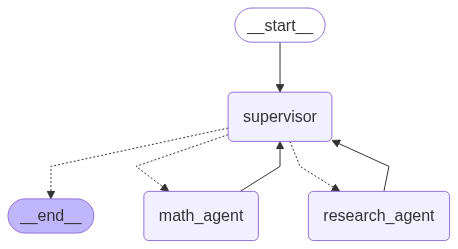

In [12]:
from IPython.display import display, Image

display(Image(supervisor.get_graph().draw_mermaid_png()))

Let's now run it with a query that requires both agents:

* research agent will look up the necessary GDP information
* math agent will perform division to find the percentage of Cape Town GDP, as requested

In [13]:
for chunk in supervisor.stream(
    {
        "messages": [
            {
                "role": "user",
                "content": "find South African and Western Cape GDP in 2024. what % of South African GDP was Western Cape province?",
            }
        ]
    },
):
    pretty_print_messages(chunk, last_message=True)

final_message_history = chunk["supervisor"]["messages"]

Update from node supervisor:


================================= Tool Message =================================
Name: transfer_to_research_agent

Successfully transferred to research_agent


Update from node research_agent:


================================= Tool Message =================================
Name: transfer_back_to_supervisor

Successfully transferred back to supervisor


Update from node supervisor:


================================== Ai Message ==================================
Name: supervisor

The Western Cape province contributed approximately 0.31% ($1.3 billion) to the South African GDP in 2024.




## 3. Create supervisor from scratch

Let's now implement this same multi-agent system from scratch. We will need to:
* Set up how the supervisor communicates with individual agents
* Create the supervisor agent
* Combine supervisor and worker agents into a single multi-agent graph.

#### Set up agent communication
We will need to define a way for the supervisor agent to communicate with the worker agents. A common way to implement this in multi-agent architectures is using handoffs, where one agent hands off control to another. Handoffs allow you to specify:

* **destination**: target agent to transfer to
* **payload**: information to pass to that agent

We will implement handoffs via handoff tools and give these tools to the supervisor agent: when the supervisor calls these tools, it will hand off control to a worker agent, passing the full message history to that agent.

In [14]:
from langchain_core.tools import tool, InjectedToolCallId
from langgraph.prebuilt import InjectedState
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.types import Command
from typing import Annotated

def create_handoff_tool(*, agent_name: str, description: str | None = None):
    name = f"transfer_to_{agent_name}"
    description = description or f"Ask {agent_name} for help."

    @tool(name, description=description)
    def handoff_tool(
        state: Annotated[MessagesState, InjectedState],
        tool_call_id: Annotated[str, InjectedToolCallId],
    ) -> Command:
        tool_message = {
            "role": "tool",
            "content": f"Successfully transferred to {agent_name}",
            "name": name,
            "tool_call_id": tool_call_id,
        }
        # highlight-next-line
        return Command(
            # highlight-next-line
            goto=agent_name,  # (1)!
            # highlight-next-line
            update={**state, "messages": state["messages"] + [tool_message]},  # (2)!
            # highlight-next-line
            graph=Command.PARENT,  # (3)!
        )

    return handoff_tool

# Handoffs
assign_to_research_agent = create_handoff_tool(
    agent_name="research_agent",
    description="Assign task to a researcher agent.",
)

assign_to_math_agent = create_handoff_tool(
    agent_name="math_agent",
    description="Assign task to a math agent.",
)

1. Name of the agent or node to hand off to.
2. Take the agent's messages and add them to the parent's state as part of the handoff. The next agent will see the parent state.
3. Indicate to LangGraph that we need to navigate to agent node in a parent multi-agent graph.

### Create supervisor agent

Then, let's create the supervisor agent with the handoff tools we just defined. 

In [15]:
supervisor_agent = create_react_agent(
    model="openai:gpt-3.5-turbo",
    tools=[assign_to_research_agent, assign_to_math_agent],
    prompt=(
        "You are a supervisor managing two agents:\n"
        "- a research agent. Assign research-related tasks to this agent\n"
        "- a math agent. Assign math-related tasks to this agent\n"
        "Assign work to one agent at a time, do not call agents in parallel.\n"
        "Do not do any work yourself."
    ),
    name="supervisor",
)

### Create multi-agent graph

Putting this all together, let's create a graph for our overall multi-agent system. We will add the supervisor and the individual agents as subgraph nodes.

In [16]:
from langgraph.graph import END

# Define the multi-agent supervisor graph
supervisor = (
    StateGraph(MessagesState)
    # NOTE: `destinations` is only needed for visualization and doesn't affect runtime behavior
    .add_node(supervisor_agent, destinations=("research_agent", "math_agent", END))
    .add_node(research_agent)
    .add_node(math_agent)
    .add_edge(START, "supervisor")
    # always return back to the supervisor
    .add_edge("research_agent", "supervisor")
    .add_edge("math_agent", "supervisor")
    .compile()
)

Notice that we've added explicit edges from worker agents back to the supervisor — this means that they are guaranteed to return control back to the supervisor. If you want the agents to respond directly to the user (i.e., turn the system into a router, you can remove these edges).

Let's look at our multi-agent graph.

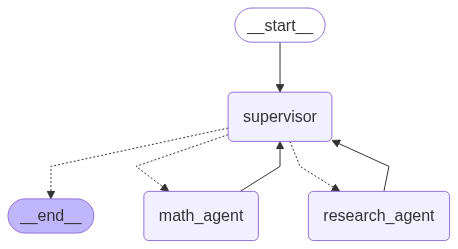

In [17]:
from IPython.display import display, Image

display(Image(supervisor.get_graph().draw_mermaid_png()))

Let's run our supervisor agent.

In [18]:
for chunk in supervisor.stream(
    {
        "messages": [
            {
                "role": "user",
                "content": "find South African and Western Cape GDP in 2024. what % of South African GDP was Western Cape?",
            }
        ]
    },
):
    pretty_print_messages(chunk, last_message=True)

final_message_history = chunk["supervisor"]["messages"]

Update from node supervisor:


================================= Tool Message =================================
Name: transfer_to_research_agent

Successfully transferred to research_agent


Update from node research_agent:


================================== Ai Message ==================================
Name: research_agent

The calculation for the Western Cape GDP as a percentage of the South African GDP in 2024 is 5.43%. 

Therefore, the Western Cape's GDP constituted approximately 5.43% of the South African GDP in 2024.


Update from node supervisor:


================================= Tool Message =================================
Name: transfer_to_math_agent

Successfully transferred to math_agent


Update from node math_agent:


================================== Ai Message ==================================
Name: math_agent

The percentage of Western Cape GDP in relation to South African GDP in 2024 is approximately 1.3%.


Update from node supervisor:


======================

Let's have a look at the full message history.

In [19]:
for message in final_message_history:
    message.pretty_print()

================================ Human Message =================================

find South African and Western Cape GDP in 2024. what % of South African GDP was Western Cape?
================================== Ai Message ==================================
Name: supervisor
Tool Calls:
  transfer_to_research_agent (call_fimaQnxEFjYLD8sL2cFxtd7f)
 Call ID: call_fimaQnxEFjYLD8sL2cFxtd7f
  Args:
================================= Tool Message =================================
Name: transfer_to_research_agent

Successfully transferred to research_agent
================================== Ai Message ==================================
Name: research_agent
Tool Calls:
  tavily_search (call_LBrBlyIsP4SbkK52Gn6MsMPZ)
 Call ID: call_LBrBlyIsP4SbkK52Gn6MsMPZ
  Args:
    query: South African GDP in 2024
    search_depth: advanced
  tavily_search (call_mHXv8iI6MvhFbo8hLyNgdQBS)
 Call ID: call_mHXv8iI6MvhFbo8hLyNgdQBS
  Args:
    query: Western Cape GDP in 2024
    search_depth: advanced
=============

## 4. Create delegation tasks

So far the individual agents relied on interpreting full message history to determine their tasks. An alternative approach is to ask the supervisor to formulate a task explicitly. We can do so by adding a `task_description` parameter to the `handoff_tool` function.

In [20]:
from langgraph.types import Send


def create_task_description_handoff_tool(
    *, agent_name: str, description: str | None = None
):
    name = f"transfer_to_{agent_name}"
    description = description or f"Ask {agent_name} for help."

    @tool(name, description=description)
    def handoff_tool(
        # this is populated by the supervisor LLM
        task_description: Annotated[
            str,
            "Description of what the next agent should do, including all of the relevant context.",
        ],
        # these parameters are ignored by the LLM
        state: Annotated[MessagesState, InjectedState],
    ) -> Command:
        task_description_message = {"role": "user", "content": task_description}
        agent_input = {**state, "messages": [task_description_message]}
        return Command(
            # highlight-next-line
            goto=[Send(agent_name, agent_input)],
            graph=Command.PARENT,
        )

    return handoff_tool

In [22]:
assign_to_research_agent_with_description = create_task_description_handoff_tool(
    agent_name="research_agent",
    description="Assign task to a researcher agent.",
)

assign_to_math_agent_with_description = create_task_description_handoff_tool(
    agent_name="math_agent",
    description="Assign task to a math agent.",
)

supervisor_agent_with_description = create_react_agent(
    model="openai:gpt-3.5-turbo",
    tools=[
        assign_to_research_agent_with_description,
        assign_to_math_agent_with_description,
    ],
    prompt=(
        "You are a supervisor managing two agents:\n"
        "- a research agent. Assign research-related tasks to this assistant\n"
        "- a math agent. Assign math-related tasks to this assistant\n"
        "Assign work to one agent at a time, do not call agents in parallel.\n"
        "Do not do any work yourself."
    ),
    name="supervisor",
)

supervisor_with_description = (
    StateGraph(MessagesState)
    .add_node(
        supervisor_agent_with_description, destinations=("research_agent", "math_agent")
    )
    .add_node(research_agent)
    .add_node(math_agent)
    .add_edge(START, "supervisor")
    .add_edge("research_agent", "supervisor")
    .add_edge("math_agent", "supervisor")
    .compile()
)

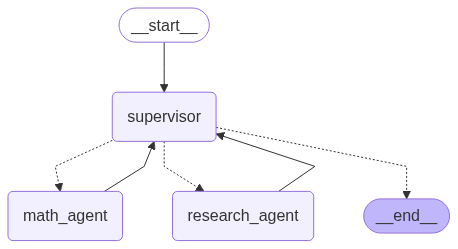

In [23]:
display(Image(supervisor_with_description.get_graph().draw_mermaid_png()))

Let's run our supervisor.

In [24]:
for chunk in supervisor_with_description.stream(
    {
        "messages": [
            {
                "role": "user",
                "content": "find South African and Western Cape GDP in 2024. what % of South African GDP was Western Cape?",
            }
        ]
    },
    subgraphs=True,
):
    pretty_print_messages(chunk, last_message=True)

Update from subgraph supervisor:


	Update from node agent:


	================================== Ai Message ==================================
	Name: supervisor
	Tool Calls:
	  transfer_to_research_agent (call_mXbIo9OGuQSm2m0jssdapJY9)
	 Call ID: call_mXbIo9OGuQSm2m0jssdapJY9
	  Args:
	    task_description: Find the GDP of South Africa and Western Cape in 2024 and calculate the percentage of Western Cape's GDP compared to the total South African GDP.


Update from subgraph research_agent:


	Update from node agent:


	================================== Ai Message ==================================
	Name: research_agent
	Tool Calls:
	  tavily_search (call_MEuw0Ysbo1cFapqS4zVEWkIG)
	 Call ID: call_MEuw0Ysbo1cFapqS4zVEWkIG
	  Args:
	    query: GDP of South Africa in 2024
	    search_depth: advanced
	  tavily_search (call_JAGzhuC36BH7f9vHUliHLcQ7)
	 Call ID: call_JAGzhuC36BH7f9vHUliHLcQ7
	  Args:
	    query: GDP of Western Cape in 2024
	    search_depth: advanced


Update from subgraph re

## References and materials

1. **agent_supervisor.ipynb** by langgraph, Github.com. [Open in Github](https://github.com/langchain-ai/langgraph/blob/main/docs/docs/tutorials/multi_agent/agent_supervisor.ipynb)